# Send a poem through a video

Read `media/poem.txt`, encode its bytes as data and Reed–Solomon parity QR codes, and embed them in a source video. Then recover the poem from a target video.


In [5]:
import importlib
from pathlib import Path

import cv2
import numpy as np
import zxingcpp

import video_processor
importlib.reload(video_processor)
from qr_solomon import QRConfig, QRDecoder, encode_message
from video_processor import VideoProcessor

In [21]:
SOURCE_VIDEO = Path("movie.mp4")
POEM_PATH = Path("media/poem.txt")
OUTPUT_VIDEO = Path("experiments/30fps/movie01.mp4")

TARGET_VIDEO = OUTPUT_VIDEO

# Outer correction: parity_shards missing QR codes can be recovered.
# Inner correction: qr_error controls damage correction within each QR image.
CONFIG = QRConfig(
    shard_bytes=64,
    parity_shards=10,
    qr_version=10,
    qr_error="H",
)
QR_CHANGE_DELAY = 0.1  # Seconds per QR code; the sequence repeats.
QR_MODULE_SIZE = 10    # Pixels per QR module.
STRENGTH = 0.1      # Brightness offset as a fraction of 255.


## Read the poem and create QR codes

The file is read as bytes to preserve its exact UTF-8 contents and line endings. Each QR code carries one data or parity shard. The selected QR version determines the rendered size; reduce `QR_MODULE_SIZE` if it does not fit the source video.


In [22]:
poem_bytes = POEM_PATH.read_bytes()
qr_codes = encode_message(poem_bytes, CONFIG)
data_shards = len(qr_codes) - CONFIG.parity_shards

print(f"Poem: {len(poem_bytes)} bytes")
print(f"QR codes: {data_shards} data + {CONFIG.parity_shards} parity = {len(qr_codes)} total")
print(f"One full sequence: {len(qr_codes) * QR_CHANGE_DELAY:.2f} seconds")


Poem: 625 bytes
QR codes: 10 data + 10 parity = 20 total
One full sequence: 2.00 seconds


In [23]:
if SOURCE_VIDEO.resolve() == OUTPUT_VIDEO.resolve():
    raise ValueError("Choose different source and output video paths")
if QR_CHANGE_DELAY <= 0 or not np.isfinite(QR_CHANGE_DELAY):
    raise ValueError("QR_CHANGE_DELAY must be finite and greater than zero")
if type(QR_MODULE_SIZE) is not int or QR_MODULE_SIZE < 1:
    raise ValueError("QR_MODULE_SIZE must be a positive integer")

source = cv2.VideoCapture(str(SOURCE_VIDEO))
try:
    if not source.isOpened():
        raise RuntimeError(f"Could not open source video: {SOURCE_VIDEO}")
    fps = source.get(cv2.CAP_PROP_FPS)
    frame_count = source.get(cv2.CAP_PROP_FRAME_COUNT)
    width = int(source.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(source.get(cv2.CAP_PROP_FRAME_HEIGHT))
finally:
    source.release()

if not np.isfinite(fps) or fps <= 0:
    raise ValueError("Source video has an invalid frame rate")
if QR_CHANGE_DELAY < 1 / fps:
    raise ValueError("QR_CHANGE_DELAY must allow at least one source frame per QR code")
qr_width, qr_height = qr_codes[0].symbol_size(scale=QR_MODULE_SIZE, border=4)
if qr_width > width or qr_height > height:
    raise ValueError(f"QR size {qr_width}x{qr_height} exceeds video size {width}x{height}")
if frame_count <= 0 or (frame_count - 1) / fps < (len(qr_codes) - 1) * QR_CHANGE_DELAY:
    raise ValueError("Source video is too short for a full QR sequence; use a longer video or shorter delay")

processor = VideoProcessor(str(SOURCE_VIDEO), qr_codes)
processor.QR_CHANGE_DELAY = QR_CHANGE_DELAY
processor.QR_MODULE_SIZE = QR_MODULE_SIZE
processor.STRENGTH = STRENGTH
processor.output(str(OUTPUT_VIDEO), double_fps=False, use_skip=False)
print(f"Created: {OUTPUT_VIDEO}")


Opened: True
FPS: 30.0
Frames: 900.0
Saved 30.00 FPS video to experiments/30fps/movie01.mp4
Created: experiments/30fps/movie01.mp4


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

## Recover the message from a target video

Each scanned QR packet is pushed into a fresh `QRDecoder`. Duplicate packets do not advance recovery. Scanning stops when the decoder returns a complete message.


In [6]:
def decode_video(cap):
    print("Capture FPS:", cap.get(cv2.CAP_PROP_FPS))
    decoder = QRDecoder()
    previous = None
    recovered_message = None
    frames_read = 0
    packets_read = 0

    try:
        if not cap.isOpened():
            raise RuntimeError(f"Could not open target video")
        print(f"Reading")

        while recovered_message is None:
            ok, frame = cap.read()
            if not ok:
                break
            frames_read += 1
            v = cv2.cvtColor(cv2.resize(frame, (960, 540)), cv2.COLOR_BGR2GRAY)
            gray = cv2.bilateralFilter(v, 3, 75, 75)

            if previous is not None:
                difference = previous.astype(np.float32) - gray.astype(np.float32)
                qr_image = np.where(difference > 0, 0, 255).astype(np.uint8)

                for candidate in (qr_image, cv2.bitwise_not(qr_image)):
                    results = zxingcpp.read_barcodes(
                        candidate,
                        formats=zxingcpp.BarcodeFormat.QRCode,
                    )
                    for result in results:
                        packets_read += 1
                        print(packets_read)
                        recovered_message = decoder.push(result.bytes)
                        if recovered_message is not None:
                            break
                    if recovered_message is not None:
                        print(recovered_message.decode("utf-8"))
                        decoder.reset()
                        break
            previous = gray
    finally:
        cap.release()
        cv2.destroyAllWindows()

    if recovered_message is not None:
        print(f"Recovered {len(recovered_message)} bytes after {frames_read} frames.")
        print()
        print(recovered_message.decode("utf-8"))

In [30]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))

def preprocess_frame(frame):
    # v = cv2.cvtColor(cv2.resize(frame, (960, 540)), cv2.COLOR_BGR2GRAY)
    v = cv2.resize(frame, (960, 540))[:, :, 1]
    gray = cv2.bilateralFilter(v, 3, 75, 75)
    gray = clahe.apply(gray)
    # gray = cv2.fastNlMeansDenoising(v, h=10, templateWindowSize=3, searchWindowSize=5)
    return gray
    # return v

def decode_video_buffered(cap, record_detections=False):
    detections = {}

    print("Capture FPS:", cap.get(cv2.CAP_PROP_FPS))
    decoder = QRDecoder()
    previous = None
    recovered_message = None
    frames_read = 0
    packets_read = 0

    try:
        if not cap.isOpened():
            raise RuntimeError(f"Could not open target video")
        print(f"Reading")

        prev_qr = None
        fix_kernel = np.ones((2, 2), np.uint8)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))

        while recovered_message is None or record_detections:
            ok, frame = cap.read()
            if not ok:
                break
            ok, frame2 = cap.read()
            if not ok:
                break
            frames_read += 2
            gray1 = preprocess_frame(frame)
            gray2 = preprocess_frame(frame2)

            detections[frames_read] = False

            # difference = previous.astype(np.int16) - gray.astype(np.int16)
            difference = gray2.astype(np.float32) - gray1.astype(np.float32)
            # qr_image = np.where(difference > 0, 0, 255).astype(np.uint8)

            abs_diff = np.abs(difference)
            # abs_diff_uint8 = np.clip(abs_diff, 0, 255).astype(np.uint8)
            abs_diff_uint8 = cv2.normalize(abs_diff, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
            _, fg_mask = cv2.threshold(abs_diff_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            qr_image = np.where(
                fg_mask > 0,
                np.where(difference < 0, 0, 255),
                255
            ).astype(np.uint8)
            # qr_image = np.where(
            #     fg_mask > 0,
            #     0,
            #     255
            # ).astype(np.uint8)

            qr_image = cv2.bitwise_not(qr_image)

            closed_img = cv2.morphologyEx(qr_image, cv2.MORPH_CLOSE, kernel)
            # closed_img = qr_image

            contours, _ = cv2.findContours(closed_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            cleaned_qr = cv2.morphologyEx(qr_image, cv2.MORPH_CLOSE, fix_kernel, iterations=1)
            cv2.imshow("Reconstructed QR", qr_image)

            rois = []
            for cnt in contours:
                x, y, w, h = cv2.boundingRect(cnt)
                aspect_ratio = float(w) / h

                if 0.8 <= aspect_ratio <= 1.2 and w > 50 and h > 50:
                    padding = 10
                    img_h, img_w = qr_image.shape
                    
                    x_start = max(0, x - padding)
                    y_start = max(0, y - padding)
                    x_end = min(img_w, x + w + padding)
                    y_end = min(img_h, y + h + padding)

                    roi = qr_image[y_start:y_end, x_start:x_end]
                    rois.append((roi, cnt))

            for roi in [[cleaned_qr]] + rois:
                reconstructed_roi = roi[0]
                # cv2.imshow("Reconstructed QR", reconstructed_roi)
                for candidate in (reconstructed_roi, cv2.bitwise_not(reconstructed_roi)):
                    results = zxingcpp.read_barcodes(
                        candidate,
                        formats=zxingcpp.BarcodeFormat.QRCode,
                    )
                    for result in results:
                        detections[frames_read] = True
                        packets_read += 1
                        print(packets_read)
                        recovered_message = decoder.push(result.bytes)
                        if recovered_message is not None:
                            break
                    if recovered_message is not None:
                        print(recovered_message.decode("utf-8"))
                        decoder.reset()
                        break
                if recovered_message is not None:
                    break
            if recovered_message is not None and not record_detections:
                    break
            # if cv2.waitKey(5) & 0xFF == ord("q"):
            #     break
    finally:
        cap.release()
        cv2.destroyAllWindows()

    if recovered_message is not None:
        print(f"Recovered {len(recovered_message)} bytes after {frames_read} frames.")
        print()
        print(recovered_message.decode("utf-8"))

    return detections

In [ ]:
cap = cv2.VideoCapture(str(TARGET_VIDEO))
decode_video_buffered(cap)

Recover message live from camera

In [43]:
CAMERA_INDEX = 0
# cap = cv2.VideoCapture(CAMERA_INDEX)
cap = cv2.VideoCapture("experiments/30fps/nature01.mp4")
cap.set(cv2.CAP_PROP_FPS, 30)
detections = decode_video_buffered(cap, record_detections=True)
print(detections)

Capture FPS: 30.0
Reading
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
by Manuel Gutiérrez Nájera

I want to die as the day declines, 
at high sea and facing the sky, 
while agony seems like a dream 
and my soul like a bird that can fly. 

To hear not, at this last moment, 
once alone with sky and sea, 
any more voices nor weeping prayers 
than the majestic beating of the waves. 

To die when the sad light retires 
its golden network from the green waves 
to be like the sun that slowly expires; 
something very luminous that fades. 

To die, and die young, before 
fleeting time removes the gentle crown, 
while life still says: "I'm yours" 
though we know with our hearts that she lies. 

42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
by Manuel Gutiérrez Nájera

I want to die as the day declines, 
at high sea and facing the sky, 
while agony seems like a dream 
and my s

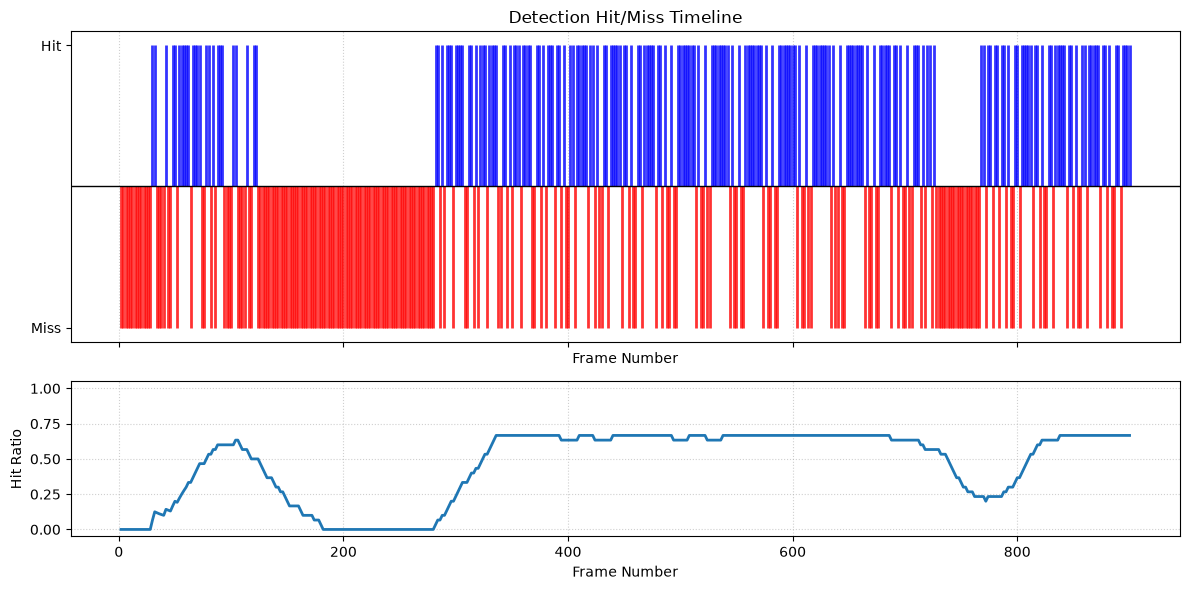

In [53]:
import matplotlib.pyplot as plt

frames = list(detections.keys())
heights = [1 if hit else -1 for hit in detections.values()]
colors = ["blue" if hit else "red" for hit in detections.values()]

hits = np.array(list(detections.values()))
hit_numeric = hits.astype(float)

window_size = 30
cumsum = np.cumsum(hit_numeric)
rolling_ratio = np.empty_like(hit_numeric)

rolling_ratio[:window_size] = cumsum[:window_size] / np.arange(
    1, window_size + 1
)
rolling_ratio[window_size:] = (
    cumsum[window_size:] - cumsum[:-window_size]
) / window_size

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

ax1.vlines(
    x=frames,
    ymin=0,
    ymax=heights,
    color=colors,
    linewidth=2,
    alpha=0.8,
)

ax1.axhline(0, color="black", linewidth=1, linestyle="-")

ax1.set_xlabel("Frame Number")
ax1.set_title("Detection Hit/Miss Timeline")
ax1.set_yticks([-1, 1])
ax1.set_yticklabels(["Miss", "Hit"])
ax1.grid(True, axis="x", linestyle=":", alpha=0.6)

ax2.plot(
    frames,
    rolling_ratio,
    linewidth=2,
)
ax2.set_xlabel("Frame Number")
ax2.set_ylabel("Hit Ratio")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()